<a href="https://colab.research.google.com/github/anapauuu31/Modulo_5-_implementacion_deep_learning/blob/main/brain_tumor_mri_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de tumores cerebrales en resonancias magnéticas con Deep Learning

A partir de una resonancia magnética del cerebro se busca identificar si hay un tumor y de qué tipo: glioma, meningioma o pituitario. Si no hay tumor, la imagen va a la clase "sin tumor".


## Dataset

[Brain Tumor Classification (MRI)](https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri) de Kaggle.

## Implementación

1. **CNN base:** sin ninguna técnica de regularización
2. **CNN regularizada:** BatchNormalization, Dropout, L2 y pesos por clase.
3. **Ajuste de hiperparámetros:** Combinaciones de learning rate y dropout.
4. **Transfer learning:** EfficientNetB0, preentrenada con ImageNet, y ajuste de capas

## 1. Configuración del entorno

In [3]:
import os, json, time, random, pathlib, hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

SEED = 42
keras.utils.set_random_seed(SEED)

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible (el entrenamiento será lento)")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Obtención del dataset


In [4]:
import pathlib

DATA_DIR = None

if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("sartajbhuvaji/brain-tumor-classification-mri")

def find_dir(root, name):
    for p in sorted(pathlib.Path(root).rglob(name)):
        if p.is_dir():
            return p
    raise FileNotFoundError(f"No se encontró la carpeta '{name}' dentro de {root}")

TRAIN_DIR = find_dir(DATA_DIR, "Training")
TEST_DIR = find_dir(DATA_DIR, "Testing")
CLASS_NAMES = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
NUM_CLASSES = len(CLASS_NAMES)
print("Entrenamiento:", TRAIN_DIR)
print("Prueba:       ", TEST_DIR)
print("Clases:", CLASS_NAMES)

Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Entrenamiento: /kaggle/input/brain-tumor-classification-mri/Training
Prueba:        /kaggle/input/brain-tumor-classification-mri/Testing
Clases: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


## 3. Análisis exploratorio de los datos

,Training,Testing
glioma_tumor,826,100
meningioma_tumor,822,115
no_tumor,395,105
pituitary_tumor,827,74
TOTAL,2870,394


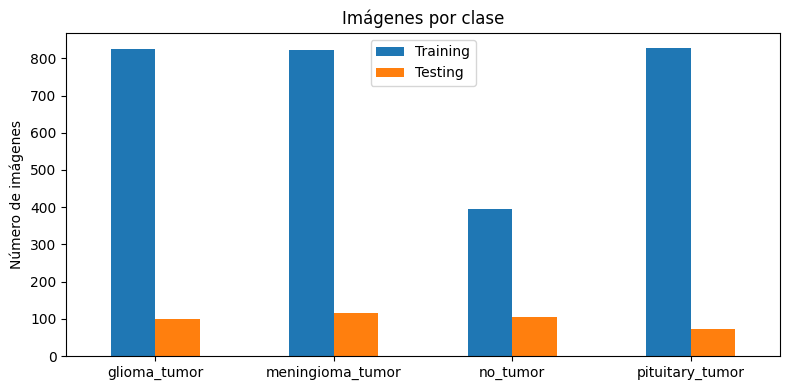

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def list_images(split_dir):
    paths, labels = [], []
    for idx, cls in enumerate(CLASS_NAMES):
        for p in sorted((split_dir / cls).iterdir()):
            if p.suffix.lower() in IMG_EXT:
                paths.append(str(p))
                labels.append(idx)
    return np.array(paths), np.array(labels)

all_train_paths, all_train_labels = list_images(TRAIN_DIR)
test_paths, y_test = list_images(TEST_DIR)

counts = pd.DataFrame({
    "Training": pd.Series(all_train_labels).value_counts().sort_index().values,
    "Testing": pd.Series(y_test).value_counts().sort_index().values,
}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
display(counts)

ax = counts.drop("TOTAL").plot.bar(figsize=(8, 4), rot=0, title="Imágenes por clase")
ax.set_ylabel("Número de imágenes")
plt.tight_layout(); plt.savefig("figures/distribucion_clases.png", dpi=120); plt.show()

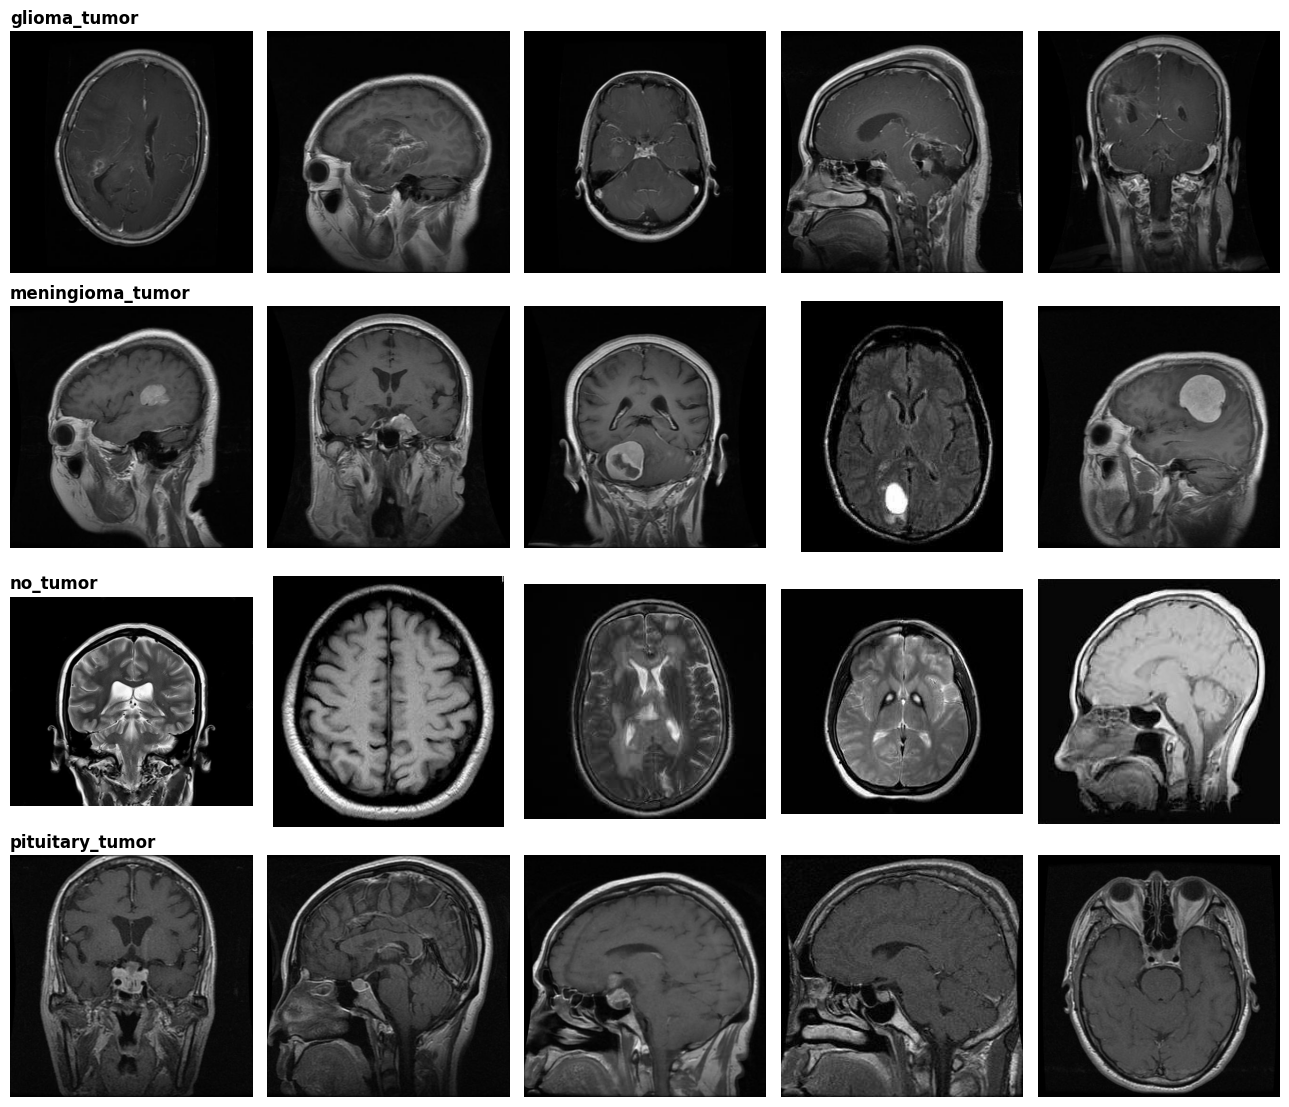

Tamaños de imagen (muestra de 300):


,ancho,alto
count,300.0,300.0
mean,484.3,485.4
std,101.8,91.8
min,200.0,208.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,926.0,851.0


Tamaños distintos en la muestra: 52


In [6]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(13, 2.8 * NUM_CLASSES))
rng = np.random.default_rng(SEED)
for i, cls in enumerate(CLASS_NAMES):
    sample = rng.choice(all_train_paths[all_train_labels == i], 5, replace=False)
    for j, p in enumerate(sample):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig("figures/ejemplos.png", dpi=100); plt.show()

sizes = [Image.open(p).size for p in rng.choice(all_train_paths, min(300, len(all_train_paths)), replace=False)]
sizes = pd.DataFrame(sizes, columns=["ancho", "alto"])
print(f"Tamaños de imagen (muestra de {len(sizes)}):")
display(sizes.describe().round(1))
print("Tamaños distintos en la muestra:", len(sizes.drop_duplicates()))

### 3.1 Calidad de los datos: imágenes duplicadas y fuga de información

Si una misma imagen aparece en entrenamiento y en prueba, la evaluación queda inflada (*data leakage*). Calculamos un hash MD5 de cada archivo para detectar duplicados exactos:
- Duplicados entre Training y Testing:se eliminan del entrenamiento para que el conjunto de prueba siga siendo independiente.
- Duplicados dentro de Training: se deja una sola copia, para que la misma imagen no termine a la vez en entrenamiento y en validación.

In [7]:
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_hashes = np.array([md5(p) for p in all_train_paths])
test_hashes = np.array([md5(p) for p in test_paths])

leak_mask = np.isin(train_hashes, test_hashes)
print(f"Imágenes de Training que también están en Testing: {leak_mask.sum()}")

groups = defaultdict(set)
for h, y in zip(train_hashes, all_train_labels):
    groups[h].add(int(y))
n_dup_groups = sum(1 for h in groups if (train_hashes == h).sum() > 1)
n_conflict = sum(1 for labels in groups.values() if len(labels) > 1)
print(f"Grupos de imágenes repetidas dentro de Training: {n_dup_groups}")
print(f"Imágenes repetidas con etiquetas distintas: {n_conflict}")

conflict_hashes = {h for h, labels in groups.items() if len(labels) > 1}
_, first_idx = np.unique(train_hashes, return_index=True)
keep = np.zeros(len(train_hashes), dtype=bool)
keep[first_idx] = True
keep &= ~leak_mask
keep &= ~np.isin(train_hashes, list(conflict_hashes))

clean_paths, clean_labels = all_train_paths[keep], all_train_labels[keep]
print(f"\nImágenes de entrenamiento: {len(all_train_paths)} -> {len(clean_paths)} tras la limpieza")

Imágenes de Training que también están en Testing: 83
Grupos de imágenes repetidas dentro de Training: 73
Imágenes repetidas con etiquetas distintas: 0

Imágenes de entrenamiento: 2870 -> 2713 tras la limpieza


## 4. División entrenamiento / validación y pipeline con tf.data

In [8]:
train_paths, val_paths, y_train, y_val = train_test_split(
    clean_paths, clean_labels, test_size=0.15, stratify=clean_labels, random_state=SEED)

print(f"Entrenamiento: {len(train_paths)} | Validación: {len(val_paths)} | Prueba: {len(test_paths)}")

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)
    return img, label

def make_ds(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_paths, y_train, shuffle=True)
val_ds = make_ds(val_paths, y_val)
test_ds = make_ds(test_paths, y_test)

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
print("Pesos por clase:", {CLASS_NAMES[i]: round(w, 3) for i, w in CLASS_WEIGHT.items()})

Entrenamiento: 2306 | Validación: 407 | Prueba: 394
Pesos por clase: {'glioma_tumor': 0.829, 'meningioma_tumor': 0.833, 'no_tumor': 2.507, 'pituitary_tumor': 0.837}


## 5. Funciones auxiliares de entrenamiento y evaluación

In [9]:
results = {}
histories = {}

def plot_history(hist, name, fine_tune_at=None):
    h = hist if isinstance(hist, dict) else hist.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(h[metric], label="entrenamiento")
        ax.plot(h["val_" + metric], label="validación")
        if fine_tune_at is not None:
            ax.axvline(fine_tune_at - 0.5, color="gray", ls="--", label="inicio fine-tuning")
        ax.set_title(f"{name} — {metric}"); ax.set_xlabel("época"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"figures/curvas_{name.split('.')[0].strip()}.png", dpi=110)
    plt.show()

def train_model(model, name, epochs, callbacks=None, class_weight=CLASS_WEIGHT, verbose=2, initial_epoch=0):
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, initial_epoch=initial_epoch,
                     callbacks=callbacks or [], class_weight=class_weight, verbose=verbose)
    elapsed = time.time() - t0
    print(f"\nTiempo de entrenamiento: {elapsed/60:.1f} min")
    return hist, elapsed

def evaluate_model(model, name, train_time=None, show=True):
    row = {"parámetros": model.count_params()}
    if train_time is not None:
        row["tiempo (min)"] = round(train_time / 60, 1)
    preds = {}
    for split, ds, y_true in [("val", val_ds, y_val), ("test", test_ds, y_test)]:
        y_pred = model.predict(ds, verbose=0).argmax(axis=1)
        preds[split] = y_pred
        row[f"{split}_accuracy"] = accuracy_score(y_true, y_pred)
        row[f"{split}_f1_macro"] = f1_score(y_true, y_pred, average="macro")
    results[name] = row
    if show:
        print(f"=== {name} ===")
        print(f"Validación -> accuracy: {row['val_accuracy']:.4f} | F1 macro: {row['val_f1_macro']:.4f}")
        print(f"Prueba     -> accuracy: {row['test_accuracy']:.4f} | F1 macro: {row['test_f1_macro']:.4f}\n")
        print("Reporte por clase (conjunto de prueba):")
        print(classification_report(y_test, preds["test"], target_names=CLASS_NAMES, digits=3))
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for ax, (split, y_true) in zip(axes, [("val", y_val), ("test", y_test)]):
            cm = confusion_matrix(y_true, preds[split])
            ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
                ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
            ax.set_title(f"{name} — matriz de confusión ({'validación' if split == 'val' else 'prueba'})")
        plt.tight_layout()
        plt.savefig(f"figures/confusion_{name.split('.')[0].strip()}.png", dpi=110)
        plt.show()
    return row

def standard_callbacks(patience=8):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ]

## 6. Modelo 1 — CNN base (línea base)


In [10]:
def build_baseline_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_base")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline = build_baseline_cnn()
baseline.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,948 (49.36 MB)

 Trainable params: 12,938,948 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
73/73 - 39s - 536ms/step - accuracy: 0.6171 - loss: 0.8844 - val_accuracy: 0.7248 - val_loss: 0.6295
Epoch 2/25
73/73 - 4s - 60ms/step - accuracy: 0.8157 - loss: 0.4661 - val_accuracy: 0.7961 - val_loss: 0.4667
Epoch 3/25
73/73 - 4s - 61ms/step - accuracy: 0.9085 - loss: 0.2321 - val_accuracy: 0.8280 - val_loss: 0.4798
Epoch 4/25
73/73 - 5s - 63ms/step - accuracy: 0.9653 - loss: 0.0985 - val_accuracy: 0.8526 - val_loss: 0.4839
Epoch 5/25
73/73 - 6s - 79ms/step - accuracy: 0.9761 - loss: 0.0661 - val_accuracy: 0.8526 - val_loss: 0.5027
Epoch 6/25
73/73 - 5s - 67ms/step - accuracy: 0.9792 - loss: 0.0621 - val_accuracy: 0.8722 - val_loss: 0.5350
Epoch 7/25
73/73 - 5s - 64ms/step - accuracy: 0.9892 - loss: 0.0390 - val_accuracy: 0.8673 - val_loss: 0.6218
Epoch 8/25
73/73 - 6s - 78ms/step - accuracy: 0.9896 - loss: 0.0274 - val_accuracy: 0.8477 - val_loss: 0.6244
Epoch 9/25
73/73 - 5s - 63ms/step - accuracy: 0.9944 - loss: 0.0242 - val_accuracy: 0.8649 - val_loss: 0.6223
Epoch 10

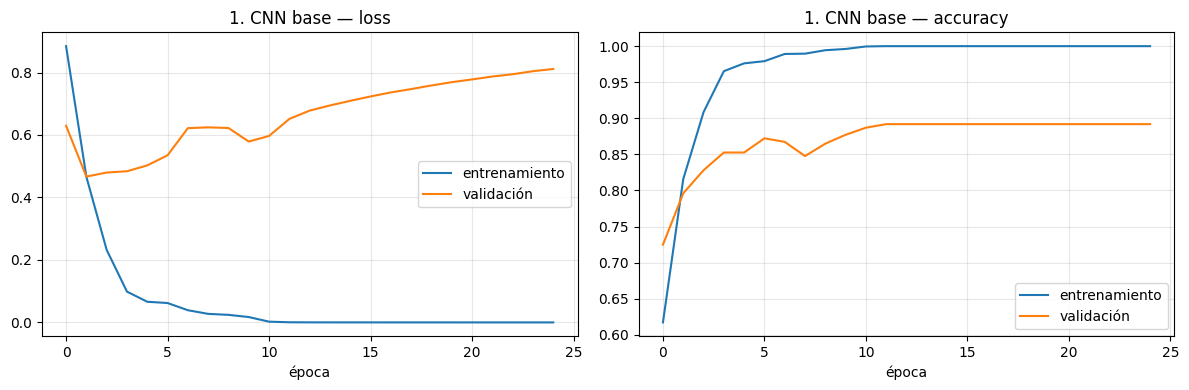

=== 1. CNN base ===
Validación -> accuracy: 0.8919 | F1 macro: 0.8801
Prueba     -> accuracy: 0.6878 | F1 macro: 0.6524

Reporte por clase (conjunto de prueba):
                  precision    recall  f1-score   support

    glioma_tumor      0.773     0.170     0.279       100
meningioma_tumor      0.620     0.922     0.741       115
        no_tumor      0.659     0.810     0.726       105
 pituitary_tumor      0.875     0.851     0.863        74

        accuracy                          0.688       394
       macro avg      0.732     0.688     0.652       394
    weighted avg      0.717     0.688     0.643       394



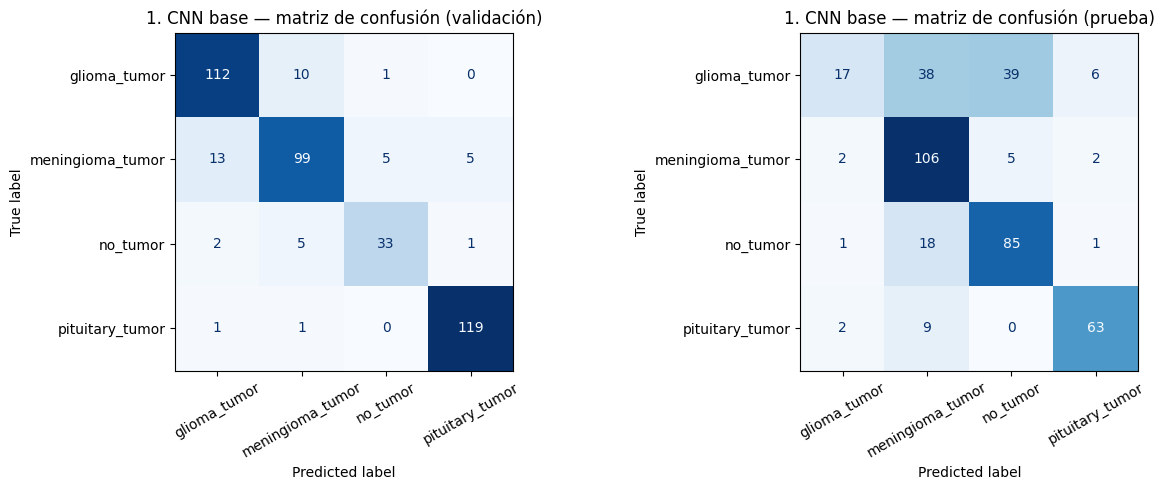

In [11]:
NAME_1 = "1. CNN base"
hist_1, time_1 = train_model(baseline, NAME_1, epochs=25, class_weight=None)
histories[NAME_1] = hist_1.history
plot_history(hist_1, NAME_1)
evaluate_model(baseline, NAME_1, time_1);

## 7. Modelo 2 — CNN regularizada



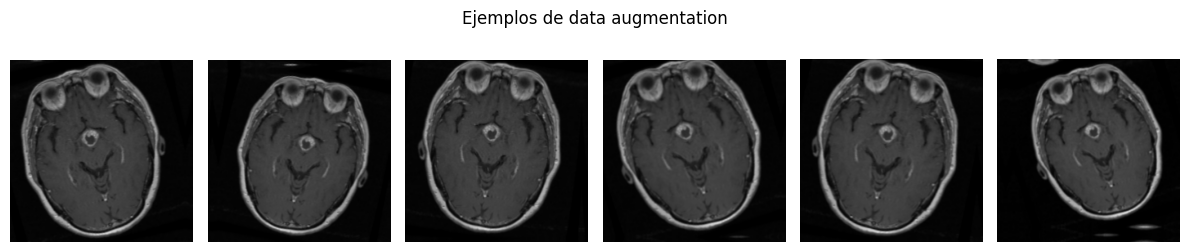

Model: "cnn_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,548 (4.61 MB)

 Trainable params: 1,206,628 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [12]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")

def conv_block(x, filters, l2):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

def build_regularized_cnn(lr=1e-3, dropout=0.4, l2=1e-4, filters=(32, 64, 128, 256)):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in filters:
        x = conv_block(x, f, l2)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(dropout / 2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_regularizada")
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

aug = make_augmentation()
sample_img, _ = next(iter(train_ds.unbatch().take(1)))
plt.figure(figsize=(12, 2.6))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(tf.cast(aug(sample_img[None], training=True)[0], tf.uint8)); plt.axis("off")
plt.suptitle("Ejemplos de data augmentation"); plt.tight_layout(); plt.show()

reg_cnn = build_regularized_cnn()
reg_cnn.summary()

Epoch 1/60
73/73 - 42s - 581ms/step - accuracy: 0.5265 - loss: 1.2009 - val_accuracy: 0.3342 - val_loss: 1.4843 - learning_rate: 0.0010
Epoch 2/60
73/73 - 22s - 296ms/step - accuracy: 0.5937 - loss: 1.0180 - val_accuracy: 0.3219 - val_loss: 2.5965 - learning_rate: 0.0010
Epoch 3/60
73/73 - 21s - 289ms/step - accuracy: 0.6409 - loss: 0.9459 - val_accuracy: 0.3022 - val_loss: 3.4746 - learning_rate: 0.0010
Epoch 4/60

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
73/73 - 21s - 287ms/step - accuracy: 0.6548 - loss: 0.9145 - val_accuracy: 0.1376 - val_loss: 5.2509 - learning_rate: 0.0010
Epoch 5/60
73/73 - 22s - 297ms/step - accuracy: 0.6882 - loss: 0.8154 - val_accuracy: 0.0983 - val_loss: 2.9167 - learning_rate: 5.0000e-04
Epoch 6/60
73/73 - 21s - 293ms/step - accuracy: 0.7121 - loss: 0.7607 - val_accuracy: 0.2948 - val_loss: 2.4596 - learning_rate: 5.0000e-04
Epoch 7/60

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
73/73 - 21s

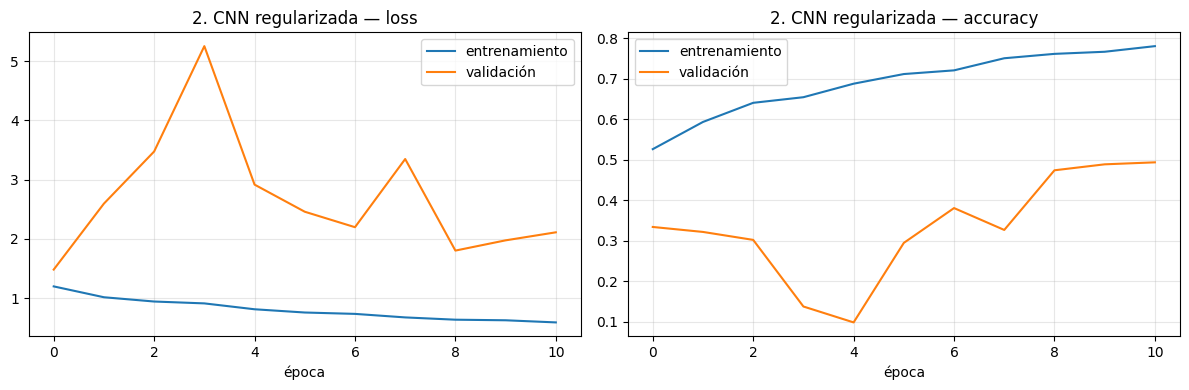

=== 2. CNN regularizada ===
Validación -> accuracy: 0.3342 | F1 macro: 0.2214
Prueba     -> accuracy: 0.3198 | F1 macro: 0.2833

Reporte por clase (conjunto de prueba):
                  precision    recall  f1-score   support

    glioma_tumor      0.273     0.500     0.353       100
meningioma_tumor      0.362     0.217     0.272       115
        no_tumor      0.357     0.438     0.393       105
 pituitary_tumor      0.385     0.068     0.115        74

        accuracy                          0.320       394
       macro avg      0.344     0.306     0.283       394
    weighted avg      0.342     0.320     0.295       394



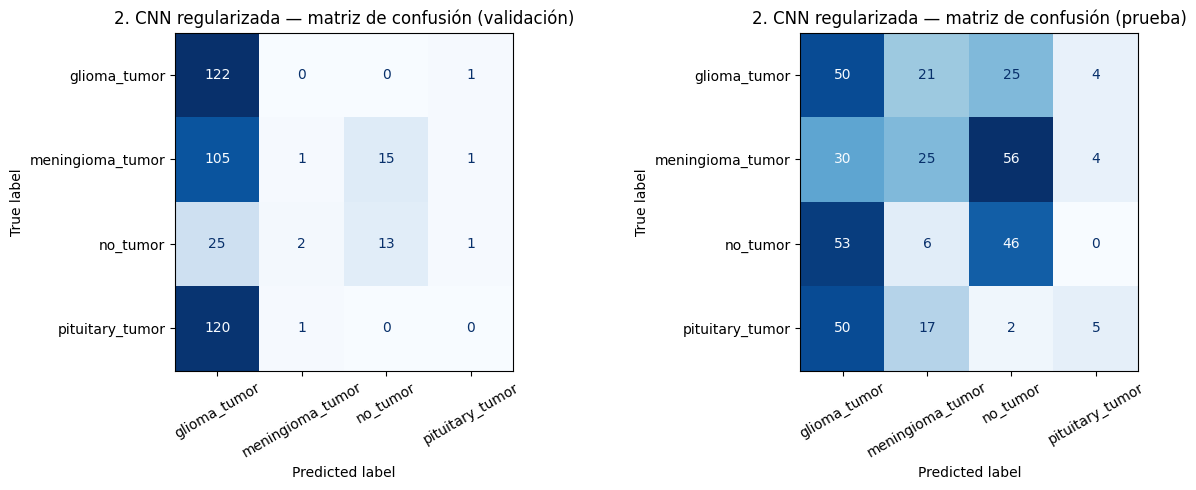

In [13]:
NAME_2 = "2. CNN regularizada"
hist_2, time_2 = train_model(reg_cnn, NAME_2, epochs=60, callbacks=standard_callbacks(patience=10))
histories[NAME_2] = hist_2.history
plot_history(hist_2, NAME_2)
evaluate_model(reg_cnn, NAME_2, time_2);

## 8. Modelo 3 — Ajuste de hiperparámetros de la CNN regularizada



In [14]:
RUN_TUNING = True
param_grid = [{"lr": lr, "dropout": d} for lr in [1e-3, 3e-4] for d in [0.3, 0.5]]

tuning_rows = []
if RUN_TUNING:
    for params in param_grid:
        keras.utils.set_random_seed(SEED)
        m = build_regularized_cnn(**params)
        h = m.fit(train_ds, validation_data=val_ds, epochs=25, class_weight=CLASS_WEIGHT,
                  callbacks=standard_callbacks(patience=6), verbose=0)
        best_epoch = int(np.argmin(h.history["val_loss"]))
        row = {**params, "épocas": len(h.history["loss"]),
               "val_loss": h.history["val_loss"][best_epoch],
               "val_accuracy": h.history["val_accuracy"][best_epoch]}
        tuning_rows.append(row)
        print(row)
        del m
        keras.backend.clear_session()

    tuning_df = pd.DataFrame(tuning_rows).sort_values("val_loss")
    display(tuning_df.round(4))
    best_params = {"lr": float(tuning_df.iloc[0]["lr"]), "dropout": float(tuning_df.iloc[0]["dropout"])}
else:
    best_params = {"lr": 1e-3, "dropout": 0.4}
print("Mejores hiperparámetros:", best_params)


Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
{'lr': 0.001, 'dropout': 0.3, 'épocas': 7, 'val_loss': 2.361063241958618, 'val_accuracy': 0.10073710232973099}

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
{'lr': 0.001, 'dropout': 0.5, 'épocas': 7, 'val_loss': 1.7718690633773804, 'val_accuracy': 0.32923832535743713}

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 14: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.

Epoch 17: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
{'lr': 0.0003, 'dropout': 0.3, 'épocas': 17, 'val_loss': 0.8608560562133789, 'val_accuracy': 0.6560196280479431}

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 7: ReduceLROnPlateau reducing learning

,lr,dropout,épocas,val_loss,val_accuracy
2,0.0003,0.3,17,0.8609,0.6560
3,0.0003,0.5,7,1.6038,0.3636
1,0.0010,0.5,7,1.7719,0.3292
0,0.0010,0.3,7,2.3611,0.1007


Mejores hiperparámetros: {'lr': 0.0003, 'dropout': 0.3}


Epoch 1/80
73/73 - 29s - 392ms/step - accuracy: 0.5577 - loss: 1.1452 - val_accuracy: 0.3022 - val_loss: 1.8891 - learning_rate: 3.0000e-04
Epoch 2/80
73/73 - 22s - 295ms/step - accuracy: 0.6661 - loss: 0.9027 - val_accuracy: 0.2998 - val_loss: 1.6979 - learning_rate: 3.0000e-04
Epoch 3/80
73/73 - 21s - 292ms/step - accuracy: 0.7069 - loss: 0.8256 - val_accuracy: 0.0786 - val_loss: 4.0058 - learning_rate: 3.0000e-04
Epoch 4/80
73/73 - 41s - 557ms/step - accuracy: 0.7272 - loss: 0.7645 - val_accuracy: 0.3120 - val_loss: 2.8616 - learning_rate: 3.0000e-04
Epoch 5/80

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
73/73 - 22s - 296ms/step - accuracy: 0.7350 - loss: 0.7358 - val_accuracy: 0.0811 - val_loss: 3.0142 - learning_rate: 3.0000e-04
Epoch 6/80
73/73 - 21s - 293ms/step - accuracy: 0.7715 - loss: 0.6348 - val_accuracy: 0.4275 - val_loss: 1.5239 - learning_rate: 1.5000e-04
Epoch 7/80
73/73 - 21s - 289ms/step - accuracy: 0.7615 - loss: 0.6739 - val_accurac

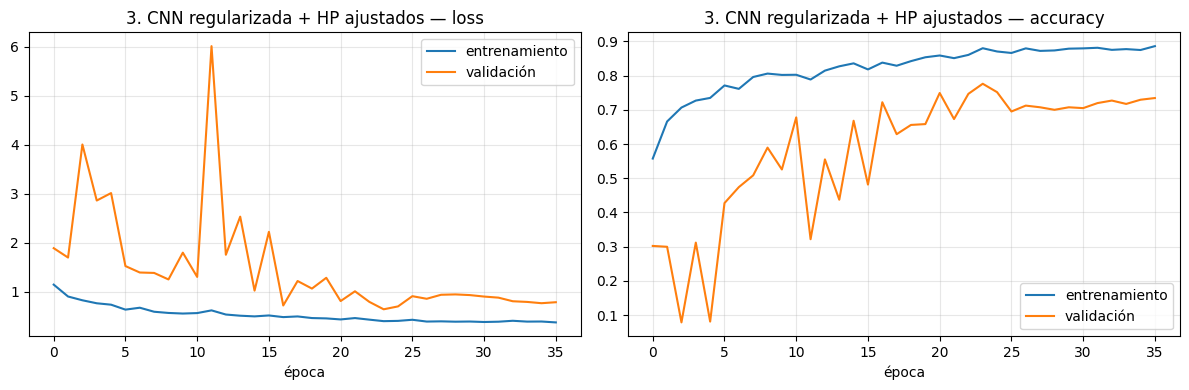

=== 3. CNN regularizada + HP ajustados ===
Validación -> accuracy: 0.7764 | F1 macro: 0.7701
Prueba     -> accuracy: 0.5102 | F1 macro: 0.4840

Reporte por clase (conjunto de prueba):
                  precision    recall  f1-score   support

    glioma_tumor      0.667     0.160     0.258       100
meningioma_tumor      0.568     0.400     0.469       115
        no_tumor      0.441     0.752     0.556       105
 pituitary_tumor      0.545     0.811     0.652        74

        accuracy                          0.510       394
       macro avg      0.555     0.531     0.484       394
    weighted avg      0.555     0.510     0.473       394



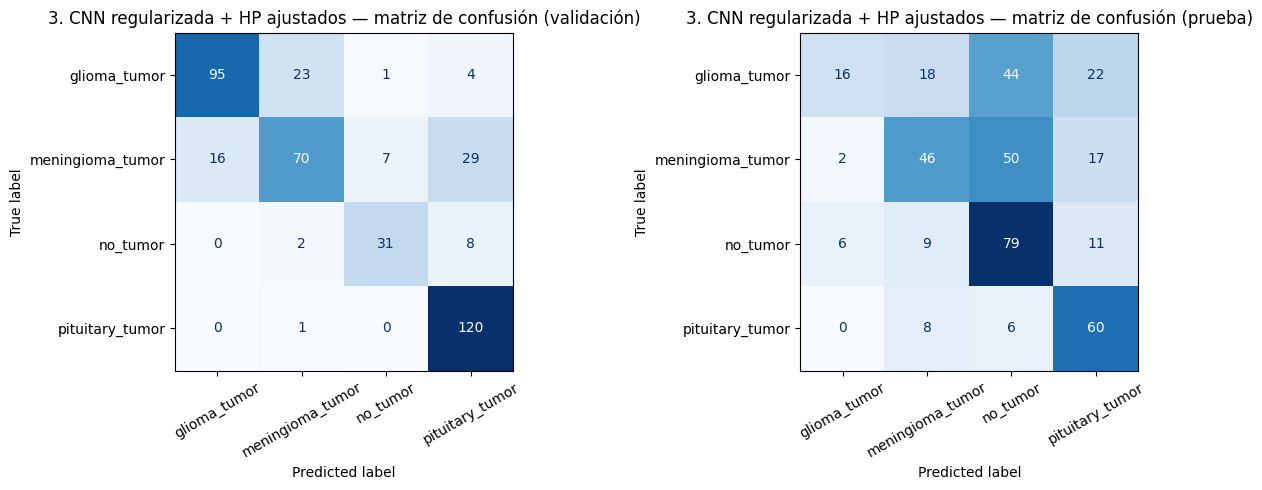

In [15]:
NAME_3 = "3. CNN regularizada + HP ajustados"
keras.utils.set_random_seed(SEED)
tuned_cnn = build_regularized_cnn(**best_params)
hist_3, time_3 = train_model(tuned_cnn, NAME_3, epochs=80, callbacks=standard_callbacks(patience=12))
histories[NAME_3] = hist_3.history
plot_history(hist_3, NAME_3)
evaluate_model(tuned_cnn, NAME_3, time_3);

## 9. Modelo 4 — Transfer learning con EfficientNetB0



In [16]:
def build_transfer_model(dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="efficientnetb0_tl")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base

keras.utils.set_random_seed(SEED)
tl_model, tl_base = build_transfer_model()
tl_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15
73/73 - 24s - 334ms/step - accuracy: 0.5577 - loss: 1.0409 - val_accuracy: 0.5799 - val_loss: 0.9509 - learning_rate: 0.0010
Epoch 2/15
73/73 - 7s - 98ms/step - accuracy: 0.7420 - loss: 0.6981 - val_accuracy: 0.6044 - val_loss: 0.9556 - learning_rate: 0.0010
Epoch 3/15
73/73 - 7s - 98ms/step - accuracy: 0.7710 - loss: 0.6065 - val_accuracy: 0.6388 - val_loss: 0.9164 - learning_rate: 0.0010
Epoch 4/15
73/73 - 8s - 104ms/step - accuracy: 0.7897 - loss: 0.5392 - val_accuracy: 0.6388 - val_loss: 0.8797 - learning_rate: 0.0010
Epoch 5/15
73/73 - 7s - 100ms/step - accuracy: 0.8049 - loss: 0.5194 - val_accuracy: 0.6757 - val_loss: 0.8246 - learning_rate: 0.0010
Epoch 6/15
73/73 - 7s - 99ms/step - accuracy: 0.8088 - loss: 0.5087 - val_accuracy: 0.6634 - val_loss: 0.8619 - learning_rate: 0.0010
Epoch 7/15
73/73 - 7s - 99ms/step - accuracy: 0.8140 - loss: 0.4782 - val_accuracy: 0.6708 - val_loss: 0.8192 - learning_rate: 0.0010
Epoch 8/15
73/73 - 7s - 95ms/step - accuracy: 0.8192 - los

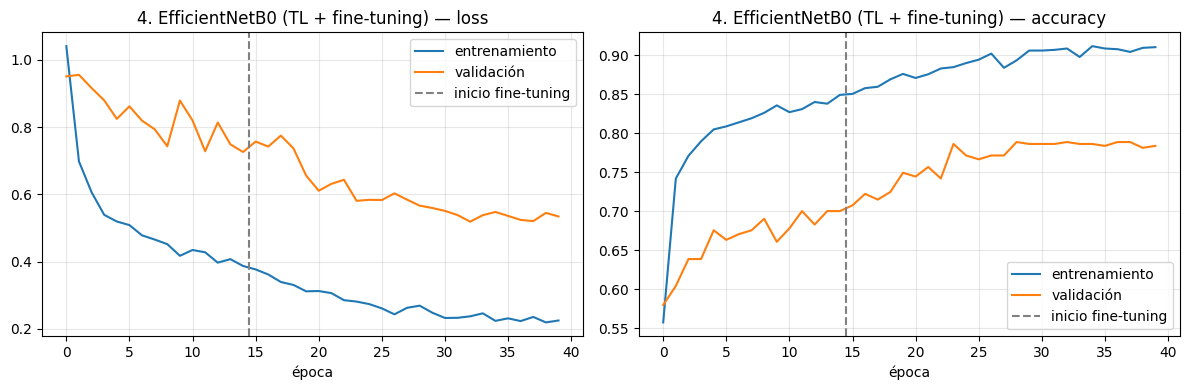

=== 4. EfficientNetB0 (TL + fine-tuning) ===
Validación -> accuracy: 0.7887 | F1 macro: 0.7953
Prueba     -> accuracy: 0.6497 | F1 macro: 0.6138

Reporte por clase (conjunto de prueba):
                  precision    recall  f1-score   support

    glioma_tumor      0.621     0.180     0.279       100
meningioma_tumor      0.667     0.765     0.713       115
        no_tumor      0.648     0.752     0.696       105
 pituitary_tumor      0.640     0.959     0.768        74

        accuracy                          0.650       394
       macro avg      0.644     0.664     0.614       394
    weighted avg      0.645     0.650     0.608       394



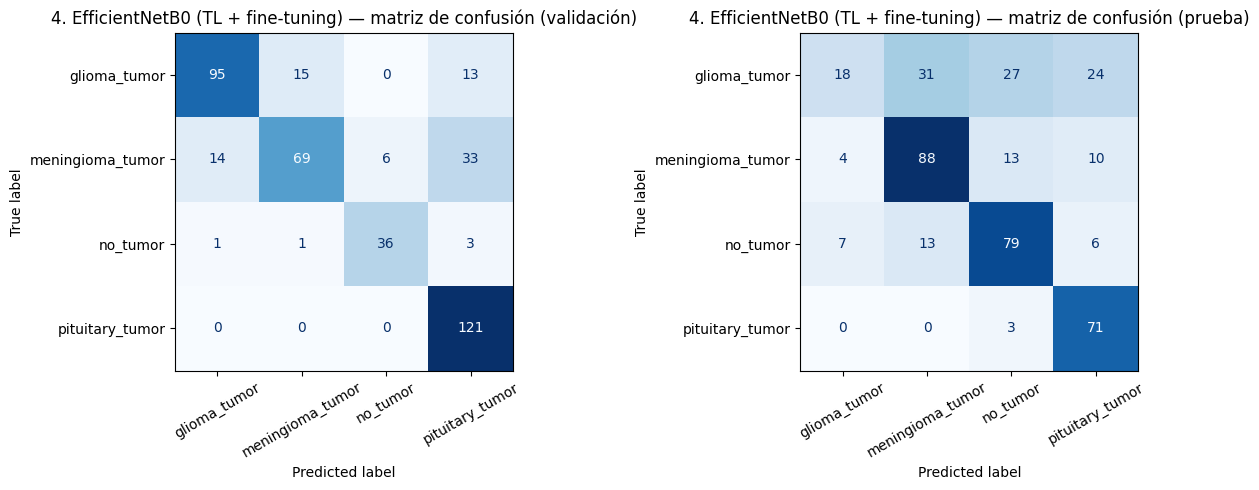

In [17]:
NAME_4 = "4. EfficientNetB0 (TL + fine-tuning)"
EPOCHS_HEAD = 15

# Fase 1:
hist_4a, time_4a = train_model(tl_model, NAME_4, epochs=EPOCHS_HEAD, callbacks=standard_callbacks(patience=5))

# Fase 2: fine-tuning de las últimas capas
FINE_TUNE_LAYERS = 60
tl_base.trainable = True
for layer in tl_base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in tl_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Capas entrenables en la base:", sum(l.trainable for l in tl_base.layers), "de", len(tl_base.layers))

start = len(hist_4a.history["loss"])
hist_4b, time_4b = train_model(tl_model, NAME_4, epochs=start + 25, initial_epoch=start,
                               callbacks=standard_callbacks(patience=8))
hist_4 = {k: hist_4a.history[k] + hist_4b.history[k] for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
histories[NAME_4] = hist_4
plot_history(hist_4, NAME_4, fine_tune_at=start)
evaluate_model(tl_model, NAME_4, time_4a + time_4b);

## 10. Comparación de modelos



,parámetros,tiempo (min),val_accuracy,val_f1_macro,test_accuracy,test_f1_macro
1. CNN base,"12,938,948",2.6,0.892,0.880,0.688,0.652
2. CNN regularizada,"1,208,548",4.3,0.334,0.221,0.320,0.283
3. CNN regularizada + HP ajustados,"1,208,548",14.9,0.776,0.770,0.510,0.484
4. EfficientNetB0 (TL + fine-tuning),"4,054,695",5.9,0.789,0.795,0.650,0.614


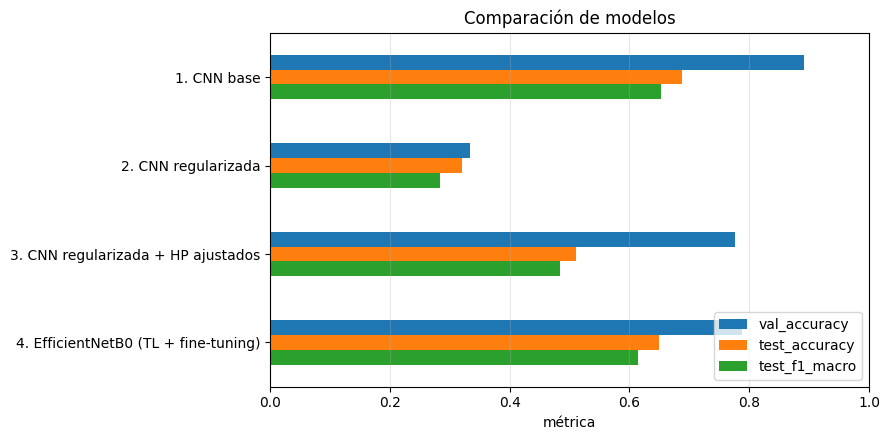

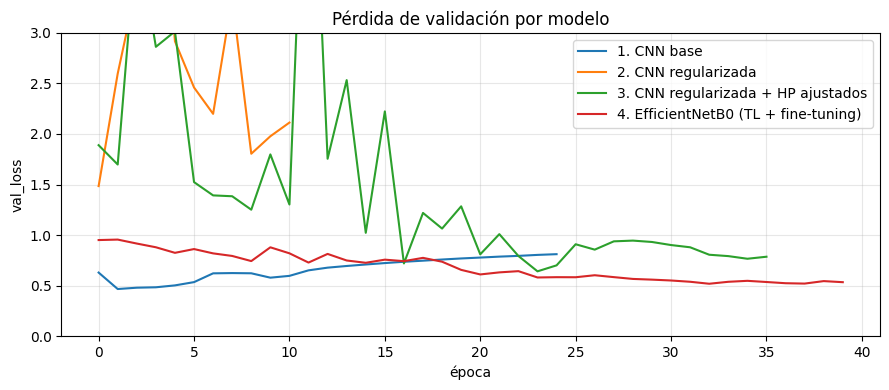

In [18]:
comparison = pd.DataFrame(results).T
display(comparison.style.format({
    "parámetros": "{:,.0f}", "tiempo (min)": "{:.1f}",
    "val_accuracy": "{:.3f}", "val_f1_macro": "{:.3f}",
    "test_accuracy": "{:.3f}", "test_f1_macro": "{:.3f}"}))
comparison.to_csv("figures/comparacion_modelos.csv")

ax = comparison[["val_accuracy", "test_accuracy", "test_f1_macro"]].plot.barh(figsize=(9, 4.5))
ax.set_xlim(0, 1); ax.set_xlabel("métrica"); ax.set_title("Comparación de modelos")
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/comparacion_modelos.png", dpi=120); plt.show()

# Pérdida de validación de todos los modelos
plt.figure(figsize=(9, 4))
for name, h in histories.items():
    plt.plot(h["val_loss"], label=name)
plt.ylim(0, min(3, max(max(h["val_loss"]) for h in histories.values())))
plt.xlabel("época"); plt.ylabel("val_loss"); plt.title("Pérdida de validación por modelo")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [19]:
models_by_name = {NAME_1: baseline, NAME_2: reg_cnn, NAME_3: tuned_cnn, NAME_4: tl_model}
BEST_NAME = comparison["val_accuracy"].astype(float).idxmax()
best_model = models_by_name[BEST_NAME]
print("Mejor modelo según validación:", BEST_NAME)

best_model.save("models/best_model.keras")
with open("models/class_names.json", "w") as f:
    json.dump({"class_names": CLASS_NAMES, "img_size": IMG_SIZE, "model": BEST_NAME}, f, indent=2)
print("Guardado en models/best_model.keras y models/class_names.json")

Mejor modelo según validación: 1. CNN base
Guardado en models/best_model.keras y models/class_names.json


## 11. Análisis

### Modelo 1: CNN base

El modelo sobreajusta muy claro. Desde la época 12 tiene 100 % de accuracy en entrenamiento y una pérdida casi cero, mientras que la pérdida de validación llega a su mínimo en la época 2 (0.47) y de ahí sube hasta 0.81. Tiene 12.9 millones de parámetros, casi todos en la capa densa después de Flatten, y con solo 2,300 imágenes eso le alcanza para memorizar el entrenamiento.

Lo más importante es la diferencia entre validación (89 %) y prueba (69 %). Como ya quité las imágenes repetidas, esa diferencia no viene de fuga de información. Viene de que las imágenes de Testing son diferentes a las de Training, y el modelo no generaliza a ellas. El peor caso es el glioma: en prueba solo detecta el 17 % (recall 0.17). Al mismo tiempo, meningioma tiene recall de 0.92 pero precisión de 0.62, lo que indica que muchas imágenes de otras clases, probablemente gliomas, se están clasificando como meningioma.

### Modelo 2: CNN regularizada

Obtuvo 33.4 % en validación y 32.0 % en prueba, mucho peor que la base, pero no porque la regularización no sirva. El problema fue cómo se entrenó:

- La pérdida de validación más baja fue en la época 1 (1.48). Después subió y bajó mucho (hasta 5.25 en la época 4), entonces el EarlyStopping cortó el entrenamiento en la época 11 y regresó los pesos de la época 1. Por eso el resultado reportado es prácticamente un modelo sin entrenar, aunque la accuracy de validación iba subiendo (0.49 en la época 11).
- La accuracy de entrenamiento subió de forma normal (de 0.53 a 0.78), pero la de validación se movió entre 0.10 y 0.49. Esto pasa con redes con BatchNormalization entrenadas desde cero: al evaluar, BatchNorm usa promedios que acumuló durante el entrenamiento, y con un learning rate de 0.001 los pesos cambian tan rápido que esos promedios todavía no representan bien a los datos.
- El learning rate bajó muy rápido por el ruido en la validación: ReduceLROnPlateau lo redujo tres veces en 10 épocas.

### Ajuste de hiperparámetros

La búsqueda confirma lo que vi en el modelo 2: el learning rate es lo que más afecta. Con 0.001 ninguna combinación pasó de las 7 épocas, porque la validación nunca mejoró después de la primera. Con 0.0003 y dropout de 0.3 el entrenamiento fue estable, duró 17 épocas y llegó a 65.6 % en validación, el doble que el modelo 2. Un dropout de 0.5 fue demasiada regularización para una red que todavía no termina de aprender.

### Modelo 3: CNN regularizada con hiperparámetros ajustados

Al bajar el learning rate a 0.0003 el modelo mejoró mucho respecto al modelo 2: pasó de 33 % a cerca de 78 % en validación y de 32 % a 51 % en prueba. Esto confirma que el problema del modelo 2 era el learning rate y no la regularización. Aun así, la pérdida de validación siguió siendo muy inestable (en la gráfica tiene picos arriba de 3 hasta la época 15). Se estabilizó hasta la época 20, con un mínimo de alrededor de 0.64 en la época 23. Además, este modelo tiene la mayor diferencia entre validación y prueba (casi 27 puntos), así que lo que aprendió no se traslada bien a las imágenes de Testing.

### Modelo 4: EfficientNetB0 con transfer learning

De todos los modelos, este tuvo el entrenamiento más estable. Su pérdida de validación bajó de forma constante, de 0.95 a 0.53, sin los saltos de las CNN entrenadas desde cero y sin subir al final como la de la CNN base. También tiene la menor diferencia entre validación y prueba (unos 13 puntos, contra 20 de la base y 27 del modelo 3). Por eso es el modelo que mejor generaliza en términos relativos, aunque su accuracy en prueba (≈ 65 %) quedó un poco abajo de la base (69 %).

Creo que no superó a la base porque le faltó entrenamiento. El entrenamiento terminó en la época 40, que era el límite que le puse (15 épocas de la cabeza más 25 de fine-tuning), y la pérdida de validación seguía bajando. El fine-tuning también fue muy conservador: solo descongelé las últimas 60 capas y usé un learning rate de 0.00001. Por último, EfficientNet se preentrenó con fotos a color de ImageNet, que son muy distintas a una resonancia en escala de grises, así que necesita más ajuste para adaptarse.

### Predicciones

En la muestra de 12 imágenes de prueba el modelo base acertó 10. Los dos errores fueron gliomas: uno lo clasificó como meningioma y otro como "sin tumor", y ambos con 100 % de confianza. Esto coincide con el recall de 0.17 para glioma en el reporte por clase.

Que se equivoque con tanta seguridad es una consecuencia del sobreajuste: como el modelo llevó la pérdida de entrenamiento casi a cero, sus probabilidades siempre son extremas, aunque esté mal. Esto también explica por qué su pérdida de validación sube a 0.81 aunque la accuracy se mantenga en 89 %. Los pocos errores que comete tienen una confianza tan alta que la pérdida los castiga mucho. Además, el error de clasificar un glioma como "sin tumor" es el más grave en un contexto médico, porque es un tumor que no se detecta.

### Conclusiones

1. El ajuste del learning rate fue el cambio que más ayudó. Pasar de 0.001 a 0.0003 llevó la CNN regularizada de 33 % a 78 % en validación. Con BatchNormalization y data augmentation, un learning rate alto hacía que la validación fuera demasiado inestable para que EarlyStopping y ReduceLROnPlateau tomaran buenas decisiones.
2. La regularización eliminó el sobreajuste, pero en esta versión no mejoró la accuracy. Ninguno de los modelos 2 a 4 llega a memorizar el entrenamiento como la base. Sin embargo, la CNN base sigue teniendo la mejor accuracy en prueba.
3. El transfer learning dio el entrenamiento más estable y la menor diferencia entre validación y prueba. Es el modelo con más margen de mejora, porque se detuvo cuando todavía estaba aprendiendo.
4. El mayor problema es la diferencia entre Training y Testing. Los modelos 1, 3 y 4 pierden entre 13 y 27 puntos al pasar de validación a prueba, y la clase que más falla es glioma. Como ya quité las imágenes duplicadas entre ambos conjuntos, esta caída no se debe a fuga de información, sino a que las imágenes de prueba son diferentes a las de entrenamiento.




## 12. Predicciones con el modelo final

### 12.1 Predicciones sobre imágenes del conjunto de prueba

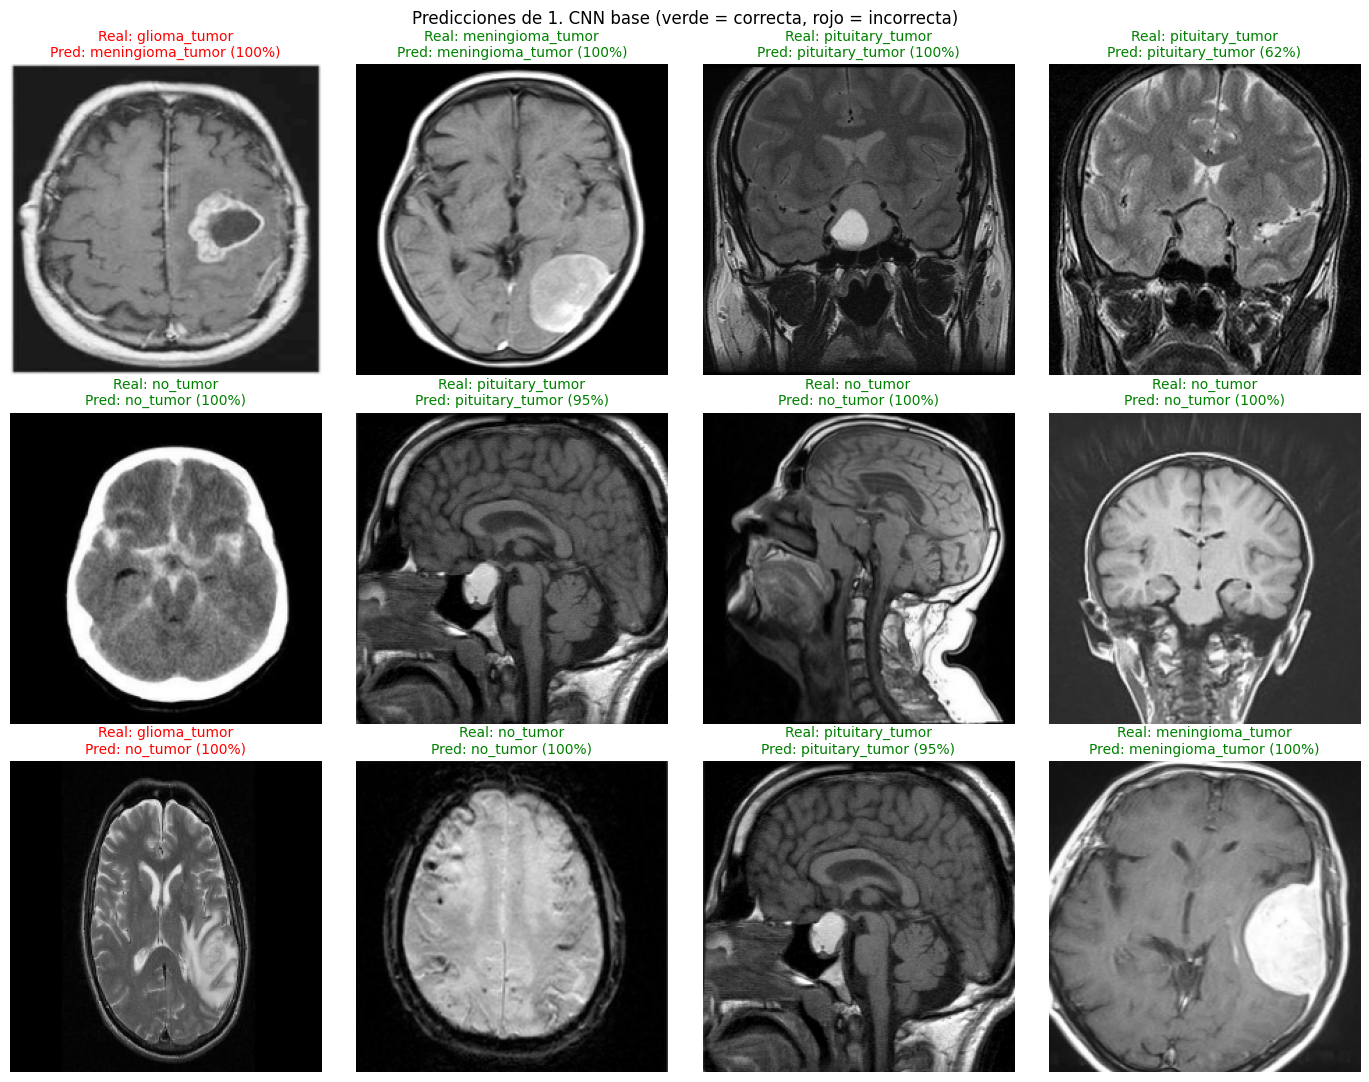

In [20]:
def predict_image(model, path):
    img, _ = load_image(tf.constant(path), 0)
    probs = model.predict(tf.cast(img, tf.float32)[None], verbose=0)[0]
    return probs, img.numpy()

rng = np.random.default_rng(7)
idx = rng.choice(len(test_paths), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, i in zip(axes.ravel(), idx):
    probs, img = predict_image(best_model, test_paths[i])
    pred, true = int(probs.argmax()), int(y_test[i])
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"Real: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]} ({probs[pred]:.0%})",
                 color="green" if pred == true else "red", fontsize=10)
plt.suptitle(f"Predicciones de {BEST_NAME} (verde = correcta, rojo = incorrecta)")
plt.tight_layout(); plt.savefig("figures/predicciones.png", dpi=100); plt.show()

In [21]:
# Predicción de una sola imagen
example = test_paths[idx[0]]
probs, _ = predict_image(best_model, example)
print("Imagen:", example)
for cls, p in sorted(zip(CLASS_NAMES, probs), key=lambda t: -t[1]):
    print(f"  {cls:<20} {p:6.1%}")

Imagen: /kaggle/input/brain-tumor-classification-mri/Testing/glioma_tumor/image(28).jpg
  meningioma_tumor     100.0%
  no_tumor               0.0%
  pituitary_tumor        0.0%
  glioma_tumor           0.0%


### 12.2 Interfaz gráfica

In [22]:
!pip install -q gradio

In [25]:
import gradio as gr

def classify(image):
    if image is None:
        return {}
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    img = tf.image.resize(tf.convert_to_tensor(image[..., :3]), (IMG_SIZE, IMG_SIZE))
    probs = best_model.predict(tf.cast(img, tf.float32)[None], verbose=0)[0]
    return {cls: float(p) for cls, p in zip(CLASS_NAMES, probs)}

demo = gr.Interface(
    fn=classify,
    inputs=gr.Image(type="numpy", label="Resonancia magnética"),
    outputs=gr.Label(num_top_classes=NUM_CLASSES, label="Predicción"),
    title="Clasificador de tumores cerebrales (MRI)",
    examples=[[p] for p in test_paths[idx[:4]]],
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://271c58d30c7695fbe0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusión

Entrené cuatro modelos para clasificar resonancias magnéticas del cerebro en glioma, meningioma, tumor pituitario o sin tumor. El mejor resultado en esta entrega fue el de la CNN base, con 89 % de accuracy en validación y 69 % en prueba. Esperaba que los modelos más complejos la superaran, y no fue así. Aun así, cada modelo me ayudó a entender mejor el problema.

La CNN base aprende rápido, pero memoriza el entrenamiento y se equivoca con total seguridad, sobre todo con los gliomas. Al agregar regularización eliminé ese sobreajuste, aunque descubrí que, con BatchNormalization y un learning rate alto, el entrenamiento se vuelve tan inestable que los callbacks lo detienen antes de que el modelo aprenda. Ajustar el learning rate fue el cambio que más mejoró los resultados. El transfer learning con EfficientNetB0 fue el modelo más estable y el que mejor generaliza, pero se quedó corto porque necesitaba más épocas de entrenamiento.

Encontré 83 imágenes repetidas entre entrenamiento y prueba que habrían inflado los resultados si no las hubiera quitado. Además, todos los modelos que lograron aprender pierden entre 13 y 27 puntos al pasar de validación a prueba, lo que indica que las imágenes del conjunto de prueba son distintas a las de entrenamiento. Por eso, una buena accuracy en validación no garantiza que el modelo funcione con imágenes nuevas, y eso es especialmente importante en un problema médico, donde el error más grave es no detectar un tumor.
